# 05 — Neural model with causal engine history

Second exploratory follow-up after original and upgrade-v1 test results were known. No independent generalisation claim. Models are selected using validation only; all saved test results are reported without choosing a best test seed.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
OUT=ROOT/'experiments/neural_history_v2'
FIG=OUT/'figures';FIG.mkdir(exist_ok=True)
read=lambda p:json.loads(Path(p).read_text())
result=read(OUT/'test_results.json')
search=read(OUT/'search_results.json')
selection=read(OUT/'selection.json')
print('Neural winner:',selection['models']['neural']['config'])
print('Forest winner:',selection['models']['random_forest']['config'])

Neural winner: {'name': 'history_wide_linear', 'representation': 'history', 'hidden': [128, 64], 'dropout': 0.1, 'weight_decay': 0.001, 'output': 'linear'}
Forest winner: {'name': 'history_rf_leaf10', 'representation': 'pooled_history', 'n_estimators': 300, 'min_samples_leaf': 10, 'max_depth': None}


## Causal features and architecture

For each prediction, use only its observed prefix: 56 recent-window summaries, 14 initial means, 14 recent-minus-initial changes, 14 cumulative means, 14 cumulative slopes and one observed cycle feature: **113 inputs**. No unit identity, future rows or total engine lifetime.

The selected MLP has 128 and 64 SiLU hidden units, dropout, linear output and clipping to [0,125]. The new forest gets the same history plus 84 ordered pooled-window features. Extra information and unequal tuning budgets limit architecture-only conclusions.

In [2]:
trials=pd.DataFrame([{'kind':r['kind'],'candidate':r['config']['name'],'seed 0 val RMSE':r['runs'][0]['val_rmse'],'seed 1 val RMSE':r['runs'][1]['val_rmse'],'mean val RMSE':r['mean_val_rmse']} for r in search])
display(trials.sort_values(['kind','mean val RMSE']).round(4))

,kind,candidate,seed 0 val RMSE,seed 1 val RMSE,mean val RMSE
3,neural,history_wide_linear,7.8971,7.7774,7.8372
9,neural,history_regularised_linear,7.9430,7.7648,7.8539
7,neural,pooled_wide_linear,7.9263,8.0266,7.9765
6,neural,pooled_small_linear,7.9886,8.0025,7.9955
2,neural,history_small_linear,7.9733,8.2020,8.0876
8,neural,history_regularised_sigmoid,8.2557,8.3865,8.3211
1,neural,history_wide_sigmoid,8.2314,8.4110,8.3212
4,neural,pooled_small_sigmoid,8.4126,8.4329,8.4227
5,neural,pooled_wide_sigmoid,8.4413,8.4466,8.4440
0,neural,history_small_sigmoid,8.3444,8.5586,8.4515


## Learning curves

Validation error includes the predetermined clipping used by inference. Training error is computed before clipping, with dropout active. Best-epoch weights are restored.

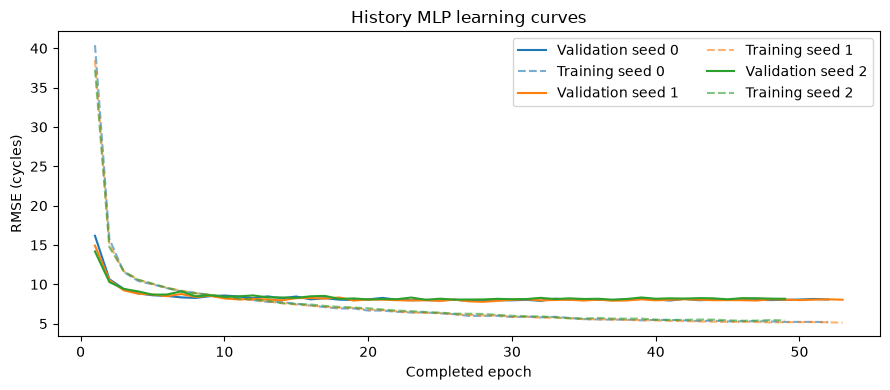

In [3]:
fig,ax=plt.subplots(figsize=(9,4))
for seed in result['seeds']:
    r=read(OUT/f"{selection['models']['neural']['config']['name']}_seed{seed}.json")
    line,=ax.plot(np.arange(1,len(r['history']['val_mse'])+1),125*np.sqrt(r['history']['val_mse']),label=f'Validation seed {seed}')
    ax.plot(np.arange(1,len(r['history']['train_mse'])+1),125*np.sqrt(r['history']['train_mse']),'--',color=line.get_color(),alpha=.6,label=f'Training seed {seed}')
ax.set(xlabel='Completed epoch',ylabel='RMSE (cycles)',title='History MLP learning curves')
ax.legend(ncol=2);fig.tight_layout();fig.savefig(FIG/'learning_curves.png',dpi=150);plt.show()

## Comparison on the already-seen FD001 test set

Compare seed means to seed means and ensembles to equally sized ensembles. Both new models have more history information than the original models. These are descriptive results on 100 test engines.

,model,seed,val_rmse,test_rmse,test_mae,test_nasa_score
0,neural,0,7.8971,10.0350,6.9400,141.2054
1,neural,1,7.7774,9.9655,7.0160,137.5162
2,neural,2,8.0417,9.2533,6.5523,124.1396
3,random_forest,0,9.5767,10.8478,7.3132,233.8163
4,random_forest,1,9.6062,10.8970,7.2924,241.7113
5,random_forest,2,9.7090,11.0391,7.3569,247.1425


,test RMSE mean,test RMSE SD,test MAE mean
model,,,
Original RF,12.1261,0.1285,8.9827
Original MLP,13.3978,0.4414,10.0507
Original LSTM,13.2676,0.4281,9.8132
Upgrade v1,12.6903,0.1970,9.6443
History RF,10.9280,0.0993,7.3208
History neural,9.7513,0.4326,6.8361


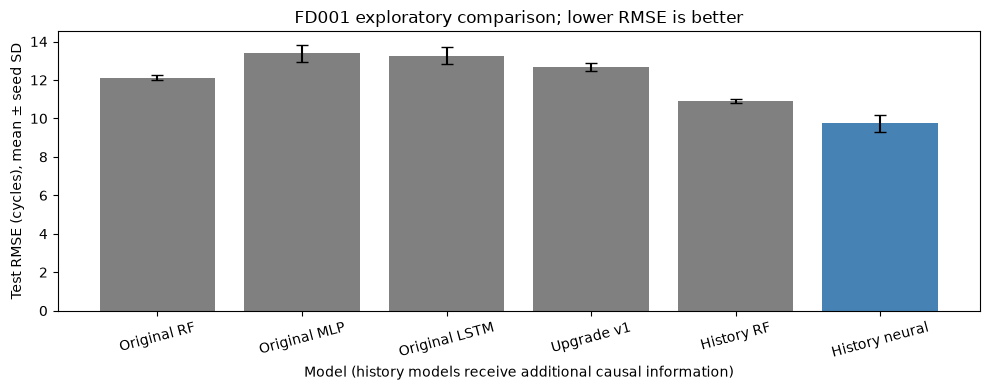

,rmse,mae,nasa_score
neural,9.6410,6.6437,129.9619
random_forest,10.9164,7.3068,240.3583


In [4]:
display(pd.read_csv(OUT/'comparison.csv').round(4))
old=read(ROOT/'results/metrics/test_metrics.json')
v1=read(ROOT/'experiments/neural_upgrade/test_results.json')['models']
rows=[]
for label,r in [('Original RF',old['random_forest']),('Original MLP',old['mlp']),('Original LSTM',old['lstm']),('Upgrade v1',v1['neural_upgrade']),('History RF',result['models']['random_forest']),('History neural',result['models']['neural'])]:
    rows.append({'model':label,'test RMSE mean':r['test_rmse']['mean'],'test RMSE SD':r['test_rmse']['std'],'test MAE mean':r['test_mae']['mean']})
summary=pd.DataFrame(rows).set_index('model');display(summary.round(4))
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(summary.index,summary['test RMSE mean'],yerr=summary['test RMSE SD'],capsize=4,color=['gray']*5+['steelblue'])
ax.set(xlabel='Model (history models receive additional causal information)',ylabel='Test RMSE (cycles), mean ± seed SD',title='FD001 exploratory comparison; lower RMSE is better')
ax.tick_params(axis='x',rotation=15);fig.tight_layout();fig.savefig(FIG/'comparison.png',dpi=150);plt.show()
ensembles=pd.DataFrame({name:r['ensemble_test'] for name,r in result['models'].items()}).T
display(ensembles.round(4))

## Errors of the selected three-neural-model ensemble

Positive residuals overestimate remaining life. The five largest errors are inspected without further tuning.

,unit,true_rul,capped_rul,neural_ensemble,error
66,67,77,77,106.186,29.186
0,1,112,112,84.103,-27.897
74,75,113,113,89.531,-23.469
94,95,128,125,101.542,-23.458
72,73,131,125,105.406,-19.594


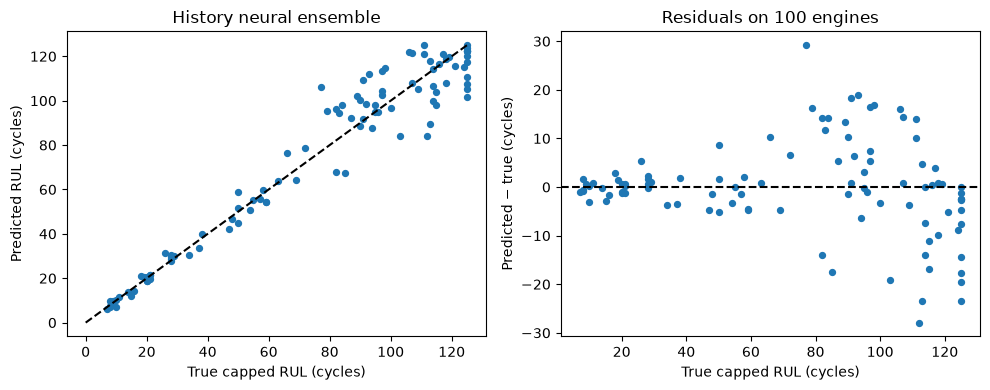

In [5]:
pred=pd.read_csv(OUT/'test_predictions.csv');pred['error']=pred.neural_ensemble-pred.capped_rul
display(pred.loc[pred.error.abs().nlargest(5).index,['unit','true_rul','capped_rul','neural_ensemble','error']].round(3))
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].scatter(pred.capped_rul,pred.neural_ensemble,s=18);axes[0].plot([0,125],[0,125],'k--')
axes[0].set(xlabel='True capped RUL (cycles)',ylabel='Predicted RUL (cycles)',title='History neural ensemble')
axes[1].scatter(pred.capped_rul,pred.error,s=18);axes[1].axhline(0,color='black',linestyle='--')
axes[1].set(xlabel='True capped RUL (cycles)',ylabel='Predicted − true (cycles)',title='Residuals on 100 engines')
fig.tight_layout();fig.savefig(FIG/'errors.png',dpi=150);plt.show()

## Interpretation

The neural model has lower mean test RMSE than the newly trained history Random Forest. The new neural mean test RMSE is 9.751, versus 12.126 for the original forest.

Full observed history adds useful information but also changes the original comparison. Results do not prove performance on real engines, other operating conditions or new independent data. The first two test evaluations were known before v2 began, and tuning budgets differ. All individual seeds and unsuccessful trials are retained.

Use: `python scripts/predict_neural_history.py examples/engine_normal.csv`. Supply complete observed history beginning at cycle 1. Predictions use neural networks only.